# Exercise 1

Restriction enzymes  are enzymes that are able to link to spcific parts of the DNA and are able to cut the DNA either in .. pattern or one of the sides of the pattermn (???)

In our simulation we will digest a piece of text and migrate those pieces

### Task

Take an arbitrary DNA sequence from NCBI (either a bacterial genome or a viral genome) to use restriction enzymes (enzyme name, recognised sequence, cleavage site)

```
      5'GAATTC  5'___G      AATTC___3'
EcoRI
      3'CTTAAG  3'___CTTAA  G___5'
  ^ First restriction enzyme discovered in the 70s


      5'GGATCC  5'___G      GATCC___3'
BamHI
      3'CCTAGG  3'___CCTAG  G___5'


        5'AAGCTT  5'___A      AGCTT___3'
HindIII
        3'TTCGAA  3'___TTCGA  A___5'


        5'TCGA  5'___T      CGA___3'
TaqI
        3'AGCT  3'___AGC  T___5'

        5'GGCC  5'___GG  CC___3'
HaeIII
        3'CCGG  3'___CC  GG___5'
```

Input: recognised sequence any restriction enzyme a DNA to be digested

Output:
1) No of cleavages any restriction enz

2) Cleavages positions & lentghs

3) A simulation of the electrophoresis gel based and the number of restriction enz. used

The output should take into consideration combinations of different restriction enzymes

### 1. Load the DNA sequence (NCBI)

In [ ]:
import os, urllib.request, urllib.parse

FASTA_FILE = "GCF_029882485_1_ASM2988248v1_genomic.fna"

def parse_fasta(text):
    """Returns (header, sequence) of the first record in a FASTA text."""
    records = [r for r in text.strip().split(">") if r.strip()]
    if not records:
        raise ValueError("Not a FASTA file")
    if len(records) > 1:
        print(f"Note: {len(records)} records in the file, using the first one")
    lines = records[0].strip().splitlines()
    return lines[0].strip(), "".join(l.strip() for l in lines[1:]).upper()


if os.path.exists(FASTA_FILE):
    with open(FASTA_FILE) as f:
        HEADER, SEQ = parse_fasta(f.read())
    print(f"Read {FASTA_FILE}")

L = len(SEQ)
print(HEADER)
print(f"Length: {L:,} bp | topology: {'circular' if CIRCULAR else 'linear'} | "
      f"GC content: {100 * (SEQ.count('G') + SEQ.count('C')) / L:.1f}%")
print("First 60 nt:", SEQ[:60])


### 2. Restriction enzymes and digestion functions

In [ ]:
import re, itertools
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Restriction enzymes: "^" marks the cleavage site on the 5'->3' (top) strand
ENZYMES = {
    "EcoRI":   "G^AATTC",
    "BamHI":   "G^GATCC",
    "HindIII": "A^AGCTT",
    "TaqI":    "T^CGA",
    "HaeIII":  "GG^CC",
}

CODES = {"A": "A", "C": "C", "G": "G", "T": "T",
         "R": "[AG]", "Y": "[CT]", "S": "[GC]", "W": "[AT]", "K": "[GT]", "M": "[AC]",
         "B": "[CGT]", "D": "[AGT]", "H": "[ACT]", "V": "[ACG]", "N": "[ACGT]"}
_COMP = str.maketrans("ACGTRYSWKMBDHVN", "TGCAYRSWMKVHDBN")


def revcomp(s):
    return s.upper().translate(_COMP)[::-1]


def parse_enzyme(notation):
    """'G^AATTC' -> ('GAATTC', 1): recognition site and cut offset on the top strand."""
    notation = notation.upper().replace(" ", "")
    if notation.count("^") != 1:
        raise ValueError(f"'{notation}': mark the cut with exactly one '^', e.g. G^AATTC")
    site = notation.replace("^", "")
    bad = set(site) - set(CODES)
    if bad:
        raise ValueError(f"'{notation}': invalid letters {bad}")
    return site, notation.index("^")


def _regex(site):
    return re.compile("(?=(" + "".join(CODES[c] for c in site) + "))")


def find_sites(seq, notation, circular=False):
    """All recognition sites of one enzyme.

    Returns a list of dicts sorted by cut position:
      site_start : 1-based position of the first nucleotide of the recognition site
      strand     : '+' (site read on the top strand) or '-' (only for non-palindromic sites)
      cut_after  : the top strand is cut between nucleotide cut_after and cut_after+1 (1-based)
      cut_index  : same cut as a 0-based index (used internally)
    """
    site, off = parse_enzyme(notation)
    L, k = len(seq), len(site)
    text = seq + seq[:k - 1] if circular else seq      # lets sites span the origin of a circle
    hits = {}

    def add(start0, cut0, strand):
        if circular:
            cut0 %= L
        elif not (0 < cut0 < L):                          # a cut at the very end does nothing
            return
        hits.setdefault(cut0, {"site_start": start0 % L + 1, "strand": strand,
                              "cut_after": cut0 or L, "cut_index": cut0})

    for m in _regex(site).finditer(text):
        add(m.start(), m.start() + off, "+")
    rc = revcomp(site)
    if rc != site:                                        # non-palindromic -> also bottom strand
        for m in _regex(rc).finditer(text):
            add(m.start(), m.start() + k - off, "-")
    return [hits[c] for c in sorted(hits)]


def fragments_from_cuts(cuts, L, circular=False):
    """cuts = sorted 0-based cut indices (cut between index c-1 and c).
    Returns list of (start, end, length) with 1-based inclusive coordinates."""
    cuts = sorted(set(cuts))
    if not cuts:
        return [(1, L, L)]
    if circular:
        frags = []
        for i, c in enumerate(cuts):
            nxt = cuts[(i + 1) % len(cuts)]
            length = (nxt - c) % L or L
            frags.append((c + 1, nxt if nxt > 0 else L, length))
        return frags
    b = [0] + cuts + [L]
    return [(b[i] + 1, b[i + 1], b[i + 1] - b[i]) for i in range(len(b) - 1)]


def digest(seq, enzyme_names, enzymes=ENZYMES, circular=False):
    """Digest `seq` with one or more enzymes at the same time."""
    cut_by = {}                                           # cut index -> enzymes cutting there
    per_enzyme = {}
    for name in enzyme_names:
        sites = find_sites(seq, enzymes[name], circular)
        per_enzyme[name] = sites
        for s in sites:
            cut_by.setdefault(s["cut_index"], []).append(name)
    cuts = sorted(cut_by)
    frags = fragments_from_cuts(cuts, len(seq), circular)
    return {"enzymes": list(enzyme_names), "per_enzyme": per_enzyme,
            "cuts": cuts, "cut_by": cut_by, "fragments": frags}


def cuts_table(d, L):
    rows = []
    for c in d["cuts"]:
        a = c or L                                        # circular: cut at the origin
        rows.append({"Cut after nt": a, "Cut between": f"{a} | {a % L + 1}",
                     "Enzyme(s)": " + ".join(d["cut_by"][c])})
    return pd.DataFrame(rows, index=pd.RangeIndex(1, len(rows) + 1, name="#"))


def fragments_table(d):
    rows = [{"Start": s, "End": e, "Length (bp)": n} for s, e, n in d["fragments"]]
    return pd.DataFrame(rows, index=pd.RangeIndex(1, len(rows) + 1, name="Fragment"))


def combo_label(names):
    return " + ".join(names)


def all_combinations(names):
    for k in range(1, len(names) + 1):
        yield from itertools.combinations(names, k)


def short_list(lengths, n=10):
    lengths = sorted(lengths, reverse=True)
    s = ", ".join(map(str, lengths[:n]))
    return s + (f", ... (+{len(lengths) - n} more)" if len(lengths) > n else "")


# Gel electrophoresis simulation
LADDER = [20000, 10000, 7000, 5000, 4000, 3000, 2000, 1500, 1000, 700, 500, 400, 300, 200, 75]
GEL_MAX_BP, GEL_MIN_BP = 30000, 50    # resolution window of a ~1% agarose gel


def migration(bp):
    """Distance travelled (0 = well, 1 = bottom). Mobility ~ -log10(size) (semi-log model)."""
    bp = np.clip(bp, GEL_MIN_BP, GEL_MAX_BP * 1.6)
    d = (np.log10(GEL_MAX_BP) - np.log10(bp)) / (np.log10(GEL_MAX_BP) - np.log10(GEL_MIN_BP))
    return 0.03 + 0.94 * np.clip(d, -0.03, 1)


def draw_gel(lanes, total_len, title="", ax=None, label_rot=60):
    """lanes = list of (label, [fragment lengths]). The first lane is drawn as the ladder.

    Band brightness ~ DNA mass in the band: every lane gets the same amount of DNA, so a
    fragment carries (length / genome length) of it; fragments of equal size co-migrate
    and add up.  Fragments under GEL_MIN_BP run off the gel.
    """
    n = len(lanes)
    if ax is None:
        _, ax = plt.subplots(figsize=(max(4, 0.85 * n + 1.5), 7))
    ax.set_facecolor("#0b0b12")
    ax.add_patch(Rectangle((0, -0.06), n, 1.1, color="#14141f", zorder=0))
    lane_w = 0.62
    for i, (label, frags) in enumerate(lanes):
        x0 = i + (1 - lane_w) / 2
        ax.add_patch(Rectangle((x0, -0.035), lane_w, 0.025, color="#2a2a3a", zorder=1))  # well
        is_ladder = i == 0
        for size, copies in Counter(frags).items():
            if size < GEL_MIN_BP:
                continue
            y = migration(size)
            if is_ladder:
                alpha = 0.95 if size in (3000, 1000) else 0.6     # reference bands
            else:
                alpha = 0.12 + 0.88 * min(1, np.sqrt(size * copies / total_len))
            ax.add_patch(Rectangle((x0 - 0.03, y - 0.008), lane_w + 0.06, 0.016,
                                   color="#ff9a3c", alpha=alpha * 0.25, lw=0, zorder=2))   # glow
            ax.add_patch(Rectangle((x0, y - 0.004), lane_w, 0.008,
                                   color="#ffe2b8", alpha=alpha, lw=0, zorder=3))           # band
    for size in LADDER:
        ax.text(-0.08, migration(size), f"{size:,}", ha="right", va="center", fontsize=7, color="0.25")
    ax.set_xlim(-0.05, n + 0.05)
    ax.set_ylim(1.03, -0.08)
    ax.set_xticks([i + 0.5 for i in range(n)])
    ax.set_xticklabels([l for l, _ in lanes], rotation=label_rot, ha="left", fontsize=8)
    ax.xaxis.tick_top()
    ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(title, fontsize=11, pad=12 + 40 * (label_rot > 0), loc="left")
    return ax


### 3. Outputs 1 & 2: number of cleavages, cleavage positions and fragment lengths (each enzyme alone)

In [ ]:
from IPython.display import display

pd.set_option("display.max_rows", 40)
single = {}
for name, notation in ENZYMES.items():
    d = digest(SEQ, [name], circular=CIRCULAR)
    single[name] = d
    print("=" * 70)
    print(f"{name}  ({notation})   ->   {len(d['cuts'])} cleavages, {len(d['fragments'])} fragments")
    print("=" * 70)
    if d["cuts"]:
        display(cuts_table(d, L))
    display(fragments_table(d).sort_values("Length (bp)", ascending=False))

EcoRI  (G^AATTC)   ->   45 cleavages, 46 fragments


,Cut after nt,Cut between,Enzyme(s)
#,,,
1,3716,3716 | 3717,EcoRI
2,8761,8761 | 8762,EcoRI
3,33368,33368 | 33369,EcoRI
4,35401,35401 | 35402,EcoRI
5,73721,73721 | 73722,EcoRI
...,...,...,...
41,340405,340405 | 340406,EcoRI
42,347093,347093 | 347094,EcoRI
43,352074,352074 | 352075,EcoRI


,Start,End,Length (bp)
Fragment,,,
5,35402,73721,38320
19,137819,166945,29127
32,273008,301899,28892
3,8762,33368,24607
29,231870,249798,17929
...,...,...,...
15,128396,129251,856
34,306802,307588,787
27,223164,223830,667


BamHI  (G^GATCC)   ->   1 cleavages, 2 fragments


,Cut after nt,Cut between,Enzyme(s)
#,,,
1,94880,94880 | 94881,BamHI


,Start,End,Length (bp)
Fragment,,,
2,94881,381277,286397
1,1,94880,94880


... (5 outputs left out)

,Start,End,Length (bp)
Fragment,,,
2710,369570,371152,1583
2763,379896,381254,1359
240,31561,32820,1260
1418,191308,192528,1221
1600,217144,218240,1097
...,...,...,...
1639,223774,223777,4
345,47472,47475,4
775,104850,104853,4


HaeIII  (GG^CC)   ->   3007 cleavages, 3008 fragments


,Cut after nt,Cut between,Enzyme(s)
#,,,
1,6,6 | 7,HaeIII
2,114,114 | 115,HaeIII
3,136,136 | 137,HaeIII
4,204,204 | 205,HaeIII
5,315,315 | 316,HaeIII
...,...,...,...
3003,380965,380965 | 380966,HaeIII
3004,381154,381154 | 381155,HaeIII
3005,381195,381195 | 381196,HaeIII


,Start,End,Length (bp)
Fragment,,,
2377,308696,310117,1422
2066,272529,273777,1249
900,126777,127868,1092
1336,181151,182155,1005
1345,183551,184545,995
...,...,...,...
1557,207823,207826,4
2329,302895,302898,4
420,56532,56535,4


### 4. Combinations of restriction enzymes (double, triple, ... digests)

Every non-empty subset of the enzymes is digested simultaneously: 2⁵ − 1 = 31 combinations for five enzymes.

In [ ]:
rows, combos = [], {}
for names in all_combinations(list(ENZYMES)):
    d = digest(SEQ, names, circular=CIRCULAR)
    combos[names] = d
    lengths = [f[2] for f in d["fragments"]]
    rows.append({
        "Enzymes": combo_label(names),
        "No. enzymes": len(names),
        "Cleavages per enzyme": ", ".join(f"{n}: {len(d['per_enzyme'][n])}" for n in names),
        "Total cleavages": len(d["cuts"]),
        "Fragments": len(lengths),
        "Fragment lengths (bp, largest first)": short_list(lengths),
    })

summary = pd.DataFrame(rows, index=pd.RangeIndex(1, len(rows) + 1))
with pd.option_context("display.max_colwidth", 120, "display.max_rows", 100):
    display(summary)

,Enzymes,No. enzymes,Cleavages per enzyme,Total cleavages,Fragments,"Fragment lengths (bp, largest first)"
1,EcoRI,1,EcoRI: 45,45,46,"38320, 29127, 28892, 24607, 17929, 16942, 15893, 15701, 15284, 14828, ... (+36 more)"
2,BamHI,1,BamHI: 1,1,2,"286397, 94880"
3,HindIII,1,HindIII: 28,28,29,"41090, 39835, 37839, 37389, 25163, 23289, 21863, 17761, 17092, 15606, ... (+19 more)"
4,TaqI,1,TaqI: 2763,2763,2764,"1583, 1359, 1260, 1221, 1097, 1052, 930, 922, 902, 861, ... (+2754 more)"
5,HaeIII,1,HaeIII: 3007,3007,3008,"1422, 1249, 1092, 1005, 995, 971, 958, 951, 859, 857, ... (+2998 more)"
6,EcoRI + BamHI,2,"EcoRI: 45, BamHI: 1",46,47,"38320, 29127, 28892, 24607, 17929, 16942, 15893, 15284, 14828, 12728, ... (+37 more)"
7,EcoRI + HindIII,2,"EcoRI: 45, HindIII: 28",73,74,"29127, 26613, 21863, 15284, 14473, 13862, 13397, 12728, 11028, 10776, ... (+64 more)"
8,EcoRI + TaqI,2,"EcoRI: 45, TaqI: 2763",2808,2809,"1583, 1359, 1260, 1221, 1097, 1052, 930, 922, 861, 797, ... (+2799 more)"
9,EcoRI + HaeIII,2,"EcoRI: 45, HaeIII: 3007",3052,3053,"1422, 1092, 1005, 971, 958, 951, 857, 855, 770, 770, ... (+3043 more)"
10,BamHI + HindIII,2,"BamHI: 1, HindIII: 28",29,30,"41090, 39835, 37839, 37389, 23289, 21863, 20760, 17761, 17092, 15606, ... (+20 more)"


In [ ]:
def show_digest(names):
    """Full report (positions + lengths) for any combination, e.g. show_digest(["EcoRI", "BamHI"])."""
    names = tuple(names)
    d = digest(SEQ, names, circular=CIRCULAR)
    print(f"{combo_label(names)}: {len(d['cuts'])} cleavages -> {len(d['fragments'])} fragments")
    for n in names:
        print(f"  {n}: {len(d['per_enzyme'][n])} cleavages")
    if d["cuts"]:
        display(cuts_table(d, L))
    display(fragments_table(d))
    return d

_ = show_digest(["EcoRI", "BamHI"])

EcoRI + BamHI: 46 cleavages -> 47 fragments
  EcoRI: 45 cleavages
  BamHI: 1 cleavages


,Cut after nt,Cut between,Enzyme(s)
#,,,
1,3716,3716 | 3717,EcoRI
2,8761,8761 | 8762,EcoRI
3,33368,33368 | 33369,EcoRI
4,35401,35401 | 35402,EcoRI
5,73721,73721 | 73722,EcoRI
...,...,...,...
42,340405,340405 | 340406,EcoRI
43,347093,347093 | 347094,EcoRI
44,352074,352074 | 352075,EcoRI


,Start,End,Length (bp)
Fragment,,,
1,1,3716,3716
2,3717,8761,5045
3,8762,33368,24607
4,33369,35401,2033
5,35402,73721,38320
...,...,...,...
43,340406,347093,6688
44,347094,352074,4981
45,352075,369016,16942


### 5. Output 3: simulated agarose gel electrophoresis

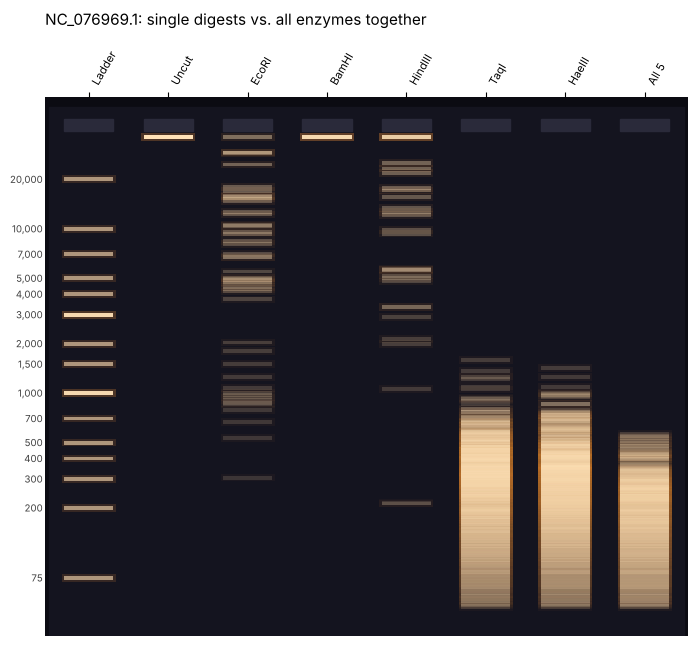

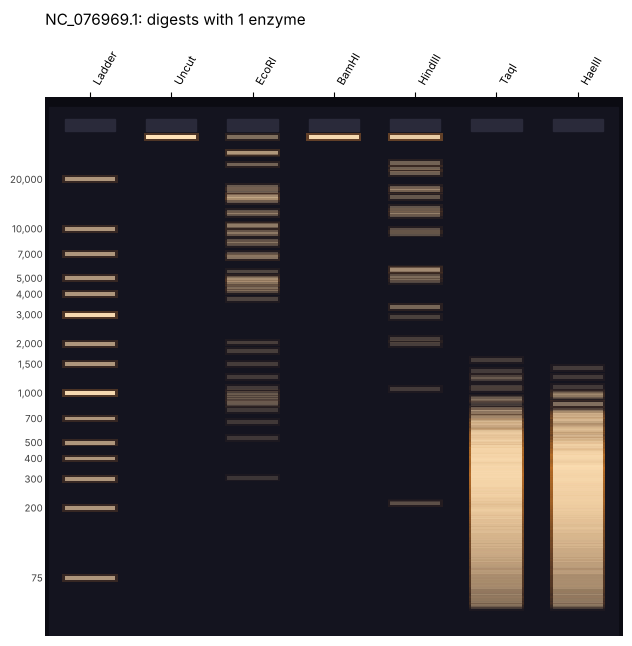

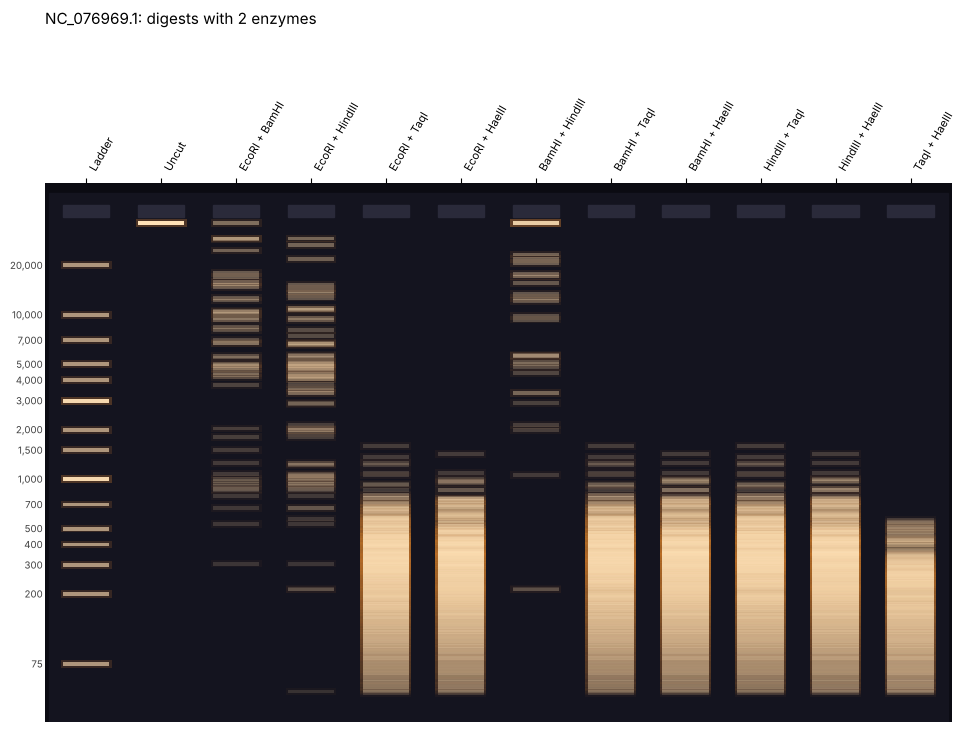

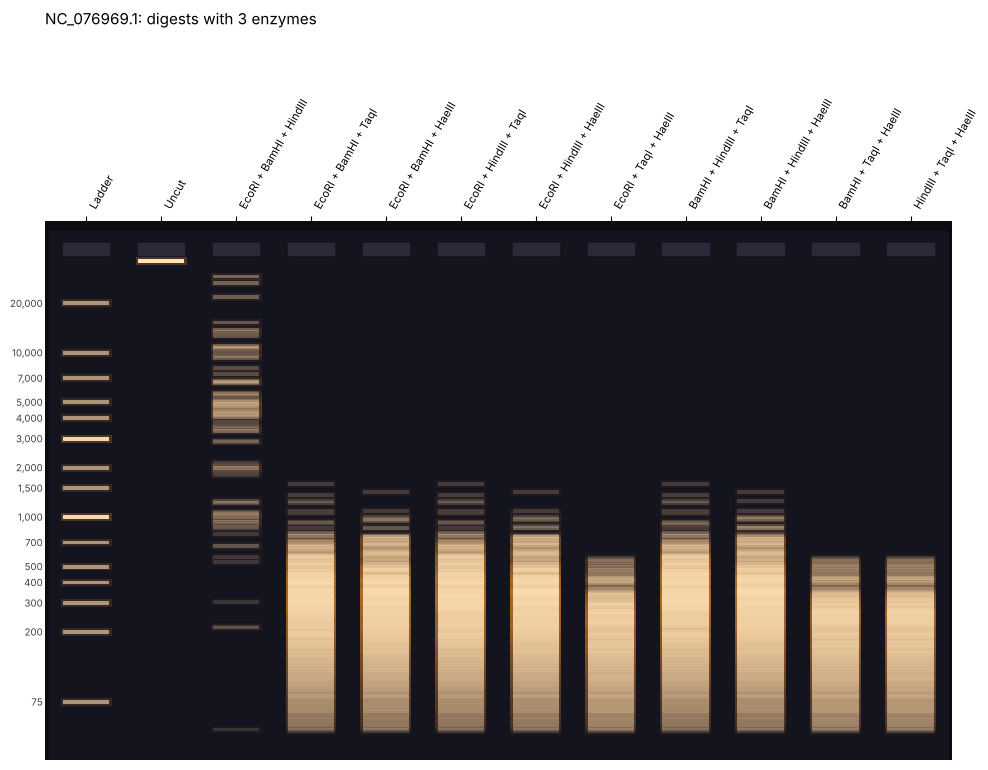

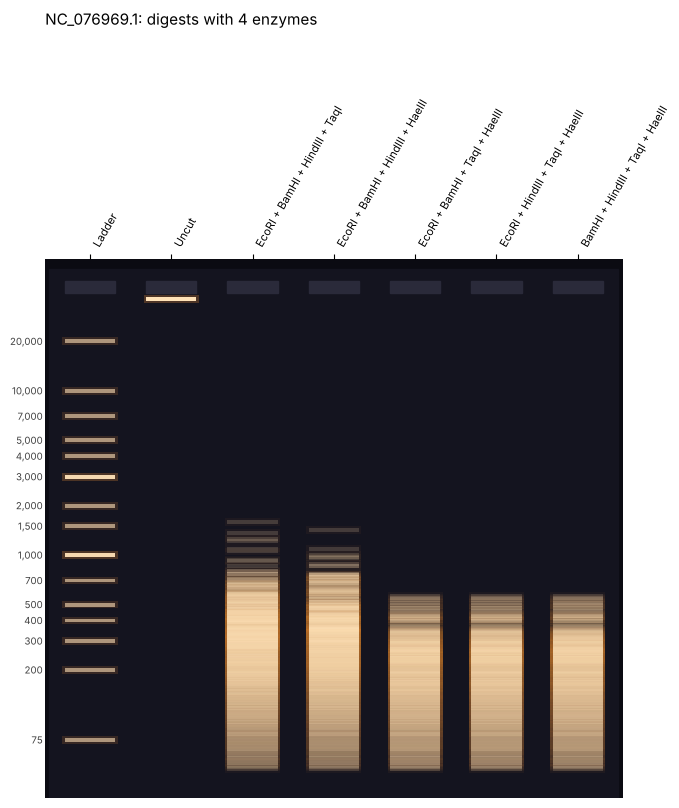

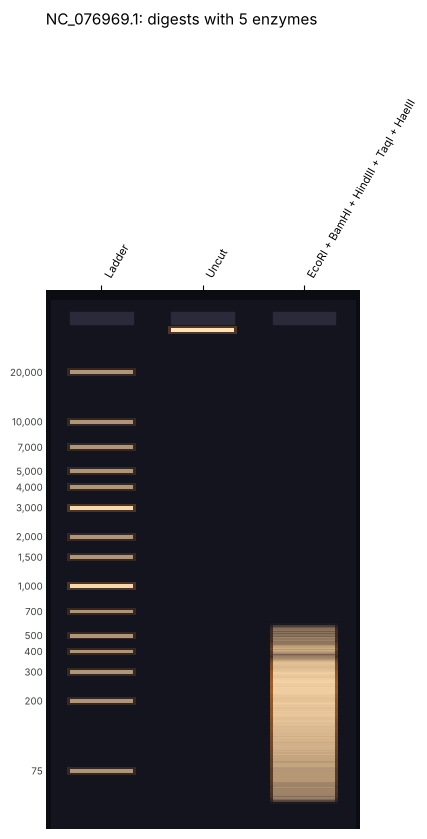

In [ ]:
def lane(names):
    return (combo_label(names), [f[2] for f in combos[tuple(names)]["fragments"]])

names = list(ENZYMES)
base = [("Ladder", LADDER), ("Uncut", [L])]

overview = base + [lane([n]) for n in names] + [("All " + str(len(names)), lane(names)[1])]
draw_gel(overview, L, f"{ACCESSION}: single digests vs. all enzymes together")
plt.show()

for k in range(1, len(names) + 1):
    lanes = base + [lane(c) for c in itertools.combinations(names, k)]
    draw_gel(lanes, L, f"{ACCESSION}: digests with {k} enzyme{'s' if k > 1 else ''}")
    plt.show()

# Exercise 2

Detection of transposones

use a random-generated DNA sequence in which you insert inverted repeats in order to simulate different transpozons.

the minimum distance between the inverted repeats composing the transpozon should be of 10 positions

the inverted repeats should be generated by ourselves

take into consideration the following cases:
1. Overlapping transposones
2. Nested transposones
3. Normal situation in which the transposones are positioned one after the other

your output should be the position of each transposone inside the sequence and it's length

In [ ]:
import random
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from IPython.display import display

COMPLEMENT = str.maketrans("ACGT", "TGCA")

def reverse_complement(seq: str) -> str:
    # Reverse complement of a DNA string.
    return seq.translate(COMPLEMENT)[::-1]

random.seed(7)

TIR_LEN = 12         # length of each inverted repeat
MIN_DIST = 10        # minimum distance between the two inverted repeats of one transposon

def random_dna(n):
    return "".join(random.choice("ACGT") for _ in range(n))

def random_tir():
    tir = random_dna(TIR_LEN)
    while tir == reverse_complement(tir):
        tir = random_dna(TIR_LEN)
    return tir


### Building the sequence from a layout

In [ ]:
def build_sequence(layout):
    # layout = the pieces of the sequence, in order:
    #   ("spacer", n)    -> n random bases
    #   ("left", "TE1")  -> left inverted repeat of TE1
    #   ("right", "TE1") -> right inverted repeat of TE1 (reverse complement of the left one)
    # putting the left/right repeats of different elements in a different order
    # gives elements one after the other, nested or overlapping
    seq, tirs, truth = "", {}, {}

    # 1. assemble the sequence and record where each element was placed
    for kind, value in layout:
        if kind == "spacer":
            seq += random_dna(value)
        elif kind == "left":
            tirs[value] = random_tir()
            truth[value] = {"TE": value, "start": len(seq) + 1, "TIR_len": TIR_LEN,
                            "left_TIR": tirs[value]}
            seq += tirs[value]
        else:
            seq += reverse_complement(tirs[value])
            truth[value]["end"] = len(seq)
            truth[value]["right_TIR"] = reverse_complement(tirs[value])

    truth = sorted(truth.values(), key=lambda t: t["start"])
    for t in truth:
        t["length"] = t["end"] - t["start"] + 1
        dist = t["length"] - 2 * TIR_LEN
        assert dist >= MIN_DIST, f"{t['TE']}: inverted repeats only {dist} bp apart"

    # 2. make sure the bases next to each element don't pair by chance
    #    (otherwise the inverted repeat would really be 1 bp longer than planned)
    #    checked outside the element and also inside it
    locked = set()                       # positions inside an inverted repeat, never changed
    for t in truth:
        locked.update(range(t["start"] - 1, t["start"] - 1 + TIR_LEN))
        locked.update(range(t["end"] - TIR_LEN, t["end"]))
    seq = list(seq)
    changed = True
    while changed:
        changed = False
        for t in truth:
            for before, after in [(t["start"] - 2, t["end"]),                           # outside
                                  (t["start"] - 1 + TIR_LEN, t["end"] - TIR_LEN - 1)]:  # inside
                if before < 0 or after >= len(seq):
                    continue
                while seq[before] == reverse_complement(seq[after]):
                    if before not in locked:
                        seq[before] = random.choice("ACGT")
                    else:
                        seq[after] = random.choice("ACGT")
                    changed = True

    truth_df = pd.DataFrame(truth)[["TE", "start", "end", "length", "TIR_len", "left_TIR", "right_TIR"]]
    return "".join(seq), truth_df


### Detecting the inverted repeats (same as Lab 6)

In [ ]:
def find_inverted_repeats(seq, min_tir=10, min_internal=10, max_te_len=200):
    # Return a list of terminal inverted repeats (candidate transposable elements).
    # Coordinates are returned 1-based and inclusive.
    seq = seq.upper()
    n, k = len(seq), min_tir

    # 1. k-mer index
    index = {}
    for p in range(n - k + 1):
        index.setdefault(seq[p:p + k], []).append(p)

    comp = {"A": "T", "T": "A", "G": "C", "C": "G"}
    found = {}

    for i in range(n - k + 1):
        target = reverse_complement(seq[i:i + k])
        for j in index.get(target, []):
            # right TIR must be downstream with an internal region in between
            if j < i + k + min_internal or (j + k - i) > max_te_len:
                continue

            # 3a. extend inward: seq[i+k+t] pairs with seq[j-1-t]
            inward = 0
            while (i + k + inward) < (j - 1 - inward) - min_internal and \
                  comp.get(seq[i + k + inward]) == seq[j - 1 - inward]:
                inward += 1
            # 3b. extend outward: seq[i-1-t] pairs with seq[j+k+t]
            outward = 0
            while i - 1 - outward >= 0 and j + k + outward < n and \
                  comp.get(seq[i - 1 - outward]) == seq[j + k + outward]:
                outward += 1

            start = i - outward
            end = j + k + outward
            tir_len = k + inward + outward
            # 4. de-duplicate (keep the longest TIR for each start/end)
            key = (start, end)
            if key not in found or found[key] < tir_len:
                found[key] = tir_len

    results = []
    for (start, end), tir_len in sorted(found.items()):
        results.append({"start": start + 1, "end": end, "length": end - start, "TIR_len": tir_len,
                        "left_TIR": seq[start:start + tir_len],
                        "right_TIR": seq[end - tir_len:end]})
    return results


### Relation between elements, plot, and running one case

In [ ]:
def add_relations(detected_df):
    # how each element is placed compared to the other ones
    relations = []
    for _, a in detected_df.iterrows():
        rel = []
        for _, b in detected_df.iterrows():
            if a["hit"] == b["hit"] or a["end"] < b["start"] or b["end"] < a["start"]:
                continue                                   # same element, or one after the other
            if a["start"] <= b["start"] and b["end"] <= a["end"]:
                rel.append(f"contains {b['hit']}")
            elif b["start"] <= a["start"] and a["end"] <= b["end"]:
                rel.append(f"nested in {b['hit']}")
            else:
                rel.append(f"overlaps {b['hit']}")
        relations.append(", ".join(rel) if rel else "one after the other")
    detected_df["relation"] = relations
    return detected_df


def plot_elements(sequence, detected_df, title):
    # put nested / overlapping elements on different rows so they don't cover each other
    rows_end, rows = [], []
    for _, r in detected_df.iterrows():
        for k, last in enumerate(rows_end):
            if r["start"] > last:
                rows_end[k] = r["end"]
                rows.append(k)
                break
        else:
            rows_end.append(r["end"])
            rows.append(len(rows_end) - 1)

    fig, ax = plt.subplots(figsize=(12, 1.5 + 0.7 * len(rows_end)))
    ax.plot([1, len(sequence)], [-1, -1], color="grey", lw=4)
    colors = plt.cm.tab10.colors
    for n, ((_, r), y) in enumerate(zip(detected_df.iterrows(), rows)):
        c = colors[n % 10]
        ax.plot([r["start"], r["end"]], [y, y], color=c, lw=2)
        ax.add_patch(mpatches.Rectangle((r["start"], y - 0.25), r["TIR_len"], 0.5, color=c))
        ax.add_patch(mpatches.Rectangle((r["end"] - r["TIR_len"], y - 0.25), r["TIR_len"], 0.5, color=c))
        ax.text((r["start"] + r["end"]) / 2, y + 0.3,
                f"{r['hit']}: {r['start']}-{r['end']} ({r['length']} bp)", ha="center", fontsize=8, color=c)
    ax.set_xlim(0, len(sequence) + 1)
    ax.set_ylim(-1.5, len(rows_end) + 0.2)
    ax.set_yticks([])
    ax.set_xlabel("position (bp)")
    ax.set_title(title, loc="left")
    plt.show()


def run_case(title, layout):
    sequence, truth_df = build_sequence(layout)

    print(f"{title}\nSequence length: {len(sequence)} bp\n")
    for i in range(0, len(sequence), 60):
        print(f"{i+1:>4}  {sequence[i:i+60]}")
    print("\nPlanted transposable elements:")
    display(truth_df)

    detected = find_inverted_repeats(sequence, min_tir=TIR_LEN, min_internal=MIN_DIST,
                                     max_te_len=len(sequence))
    detected_df = pd.DataFrame(detected)
    detected_df.insert(0, "hit", [f"hit{i+1}" for i in range(len(detected_df))])
    detected_df = add_relations(detected_df)
    print(f"Detected {len(detected_df)} inverted-repeat element(s):")
    display(detected_df)

    # check that each pair really is an inverted repeat
    for r in detected:
        assert reverse_complement(r["left_TIR"]) == r["right_TIR"]

    # compare with what was manually placed
    planted = set(zip(truth_df["start"], truth_df["end"]))
    found = set(zip(detected_df["start"], detected_df["end"]))
    print(f"Planted elements found at the exact position: {len(planted & found)}/{len(planted)}, "
          f"extra hits: {len(found - planted)}")

    plot_elements(sequence, detected_df, title)
    return sequence, truth_df, detected_df


### Example



All three cases in one sequence
Sequence length: 358 bp

   1  GCTCCATGAACTTAGCTGCTAGTGTCAGACTCGCCTCGGATCCTTACTACACTAACTTGA
  61  ACGCCTCGTGGTCAAAGAGTACTGGTAATCGTCGGCTCTTTGACCACTATCTATATAAGC
 121  AGGAGTAAGGATCCGGGAGGGGAAACATTTGTTCTCAGCCGGTGACTCCTAATGCTAAGA
 181  CATTTCCCTTCAGGGGGGGCTCCCCCGCGATGCCATAAAAGGAGTCACCGGTCTGAGCAA
 241  CCAGCTGGGAGCCCCCCCGAAGCAGGCACGACAGTGCGACACTATATCACTGTGCTAGGT
 301  TAGCTTCATCTAATGTCCCACAGTGATATAAACTAGCCGGCCAATTCGCATGATACCT

Planted transposable elements:


,TE,start,end,length,TIR_len,left_TIR,right_TIR
0,TE1,37,135,99,12,CGGATCCTTACT,AGTAAGGATCCG
1,TE2,68,107,40,12,GTGGTCAAAGAG,CTCTTTGACCAC
2,TE3,159,231,73,12,CCGGTGACTCCT,AGGAGTCACCGG
3,TE4,193,258,66,12,GGGGGGGCTCCC,GGGAGCCCCCCC
4,TE5,283,330,48,12,TATATCACTGTG,CACAGTGATATA


Detected 5 inverted-repeat element(s):


,hit,start,end,length,TIR_len,left_TIR,right_TIR,relation
0,hit1,37,135,99,12,CGGATCCTTACT,AGTAAGGATCCG,contains hit2
1,hit2,68,107,40,12,GTGGTCAAAGAG,CTCTTTGACCAC,nested in hit1
2,hit3,159,231,73,12,CCGGTGACTCCT,AGGAGTCACCGG,overlaps hit4
3,hit4,193,258,66,12,GGGGGGGCTCCC,GGGAGCCCCCCC,overlaps hit3
4,hit5,283,330,48,12,TATATCACTGTG,CACAGTGATATA,one after the other


Planted elements found at the exact position: 5/5, extra hits: 0


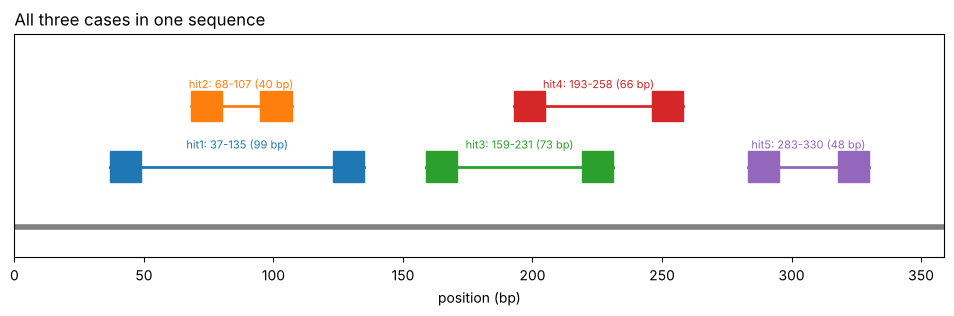

In [ ]:
# TE2 nested in TE1, TE3 overlaps TE4, TE5 on its own
MIXED = [("spacer", random.randint(20, 40)),
         ("left", "TE1"),  ("spacer", random.randint(10, 20)),
         ("left", "TE2"),  ("spacer", random.randint(MIN_DIST, 25)),
         ("right", "TE2"), ("spacer", random.randint(10, 20)),
         ("right", "TE1"), ("spacer", random.randint(15, 30)),
         ("left", "TE3"),  ("spacer", random.randint(15, 30)),
         ("left", "TE4"),  ("spacer", random.randint(15, 30)),
         ("right", "TE3"), ("spacer", random.randint(15, 30)),
         ("right", "TE4"), ("spacer", random.randint(15, 30)),
         ("left", "TE5"),  ("spacer", random.randint(MIN_DIST, 30)),
         ("right", "TE5"), ("spacer", random.randint(20, 40))]

sequence, truth_df, detected_df = run_case("All three cases in one sequence", MIXED)
